# BeningOrMalignantCNN


In [176]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report,confusion_matrix,ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers, models,Sequential
from keras.layers import Dense
import seaborn as sns
import matplotlib.pyplot as plt

#### The load_data function:
is designed for preprocessing image data for machine learning tasks. It reads images from a directory where each subdirectory represents a class, resizes them to a uniform size (default: 124x124), normalizes pixel values to the range [0, 1], and assigns integer labels based on the subdirectory structure. It handles unreadable images gracefully by skipping them and printing warnings. The function returns two NumPy arrays: one containing the processed images and another with their corresponding labels, making it suitable for preparing data for image classification models.

In [3]:
def load_data(data_dir, img_size=(124, 124)):
    images = []
    labels = []
    class_names = sorted(os.listdir(data_dir))
    
    for label, class_name in enumerate(class_names):
        class_path = os.path.join(data_dir, class_name)
        
        if not os.path.isdir(class_path):
            continue
        
        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            
            try:
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.resize(img, img_size)
                    images.append(img / 255.0)  
                    labels.append(label)      
                else:
                    print(f"Warning: Unable to read image {img_path}. Skipping...")
            
            except Exception as e:
                print(f"Error processing file {img_path}: {e}")
    
    return np.array(images), np.array(labels)

### I am using 124x124 dataset because my computational power was not enough and process was so slow on 300x300 dataset

In [5]:
train_images, train_labelsFirst = load_data('Melanoma124x124/train')
test_images, test_labels = load_data('Melanoma124x124/test')

print(f"Train Images: {train_images.shape}, Train Labels: {train_labelsFirst.shape}")
print(f"Test Images: {test_images.shape}, Test Labels: {test_labels.shape}")

Train Images: (7684, 124, 124, 3), Train Labels: (7684,)
Test Images: (1921, 124, 124, 3), Test Labels: (1921,)


In [7]:
train_labelsFirst

array([1, 1, 1, ..., 2, 2, 2])

In [9]:
test_labels

array([1, 1, 1, ..., 2, 2, 2])

### If upper values is not like 1 1 1 ... 2 2 2 than dont execute downward code

### Because of some .DS_Store file it classify like 1 and 2 so I changed them to bening = 0 and malignant = 1

In [11]:
train_labelsFirst = np.where(train_labelsFirst == 1, 0, train_labelsFirst)
train_labelsFirst = np.where(train_labelsFirst == 2, 1, train_labelsFirst)
train_labelsFirst

array([0, 0, 0, ..., 1, 1, 1])

In [13]:
test_labels = np.where(test_labels == 1, 0, test_labels)
test_labels = np.where(test_labels == 2, 1, test_labels)
test_labels

array([0, 0, 0, ..., 1, 1, 1])

### benign = 0 / malignant = 1

## The CustomCNN class:
is designed to create, compile, train, and make predictions using a Convolutional Neural Network (CNN) for binary classification tasks. It includes two convolutional layers followed by max-pooling, a flattening layer, and two fully connected layers, with a sigmoid activation in the output layer to generate probabilities for binary outputs. The class allows customization of the activation function, batch size, and learning rate, making it versatile for various image-based classification problems. Additionally, it provides methods for training the model on input data, evaluating performance with validation data, and predicting labels for new test data.

In [25]:
class CustomCNN:
    def __init__(self, input_shape, activation_function='relu', batch_size=32):
        self.batch_size = batch_size
        self.model = self._build_model(input_shape, activation_function)
    
    def _build_model(self, input_shape, activation_function):
        model = models.Sequential()

        model.add(layers.Input(shape=input_shape))
        
        model.add(layers.Conv2D(32, (3, 3), activation=activation_function, padding='same'))
        model.add(layers.MaxPooling2D((2, 2)))
        
        model.add(layers.Conv2D(64, (3, 3), activation=activation_function, padding = 'same'))
        model.add(layers.MaxPooling2D((2, 2)))
        
        model.add(layers.Flatten())
        
        model.add(layers.Dense(124, activation=activation_function))
        
        model.add(layers.Dense(1, activation='sigmoid'))  
        
        return model

    def compile(self, learning_rate):
        self.model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                           loss='binary_crossentropy',
                           metrics=['accuracy'])
    
    def summary(self):
        self.model.summary()
    
    def train(self, train_data, train_labels, validation_data, epochs):
        return self.model.fit(train_data, train_labels, 
                              validation_data=validation_data, 
                              epochs=epochs, 
                              batch_size=self.batch_size)

    def predict(self, test_data):
        """
        Make predictions using the specified batch size and return binary class labels.
        """
        # Get raw probabilities from the model
        raw_predictions = self.model.predict(test_data, batch_size=self.batch_size)
        
        # Convert probabilities to binary class labels based on a threshold (default: 0.5)
        predicted_classes = (raw_predictions > 0.5).astype(int)
        
        return predicted_classes

# plot_confusion_matrix: 
The plot_confusion_matrix function visualizes the confusion matrix for a classification task, showing the relationship between true labels (y_true) and predicted labels (y_pred). It uses a heatmap to represent the matrix, with annotations for cell values, customizable class names (default: “Benign” and “Malignant”), and a color map for better readability. The function provides a clear and structured way to evaluate the model’s performance by highlighting true positives, true negatives, false positives, and false negatives in a visually intuitive manner.

In [21]:
def plot_confusion_matrix(y_true, y_pred, class_names=None, figsize=(8, 6), cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred)
    
    custom_class_names = ["Benign", "Malignant"]
    
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, xticklabels=custom_class_names, yticklabels=custom_class_names)
    
    plt.title("Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# CNN 

### I want to evaluate the performance of the CNN model on validation data during training. To achieve this, I separate the validation data from the training data instead of using a k-fold approach, as I have limited computational resources.

In [23]:
train_data, val_data, train_labels, val_labels = train_test_split(
    train_images, train_labelsFirst, test_size=0.2, random_state=42
)
validation_data=(val_data, val_labels)

## RELU

### 32 batch - learning rate 0,005

In [27]:
cnn = CustomCNN((124,124,3),activation_function='relu', batch_size=32)

In [29]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 124, 124, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 62, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61504)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 124)            │     7,626,620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,646,137 (29.17 MB)

 Trainable params: 7,646,137 (29.17 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
cnn.compile(learning_rate = 0.005)
cnn.train(train_data,train_labels,validation_data,5)

Epoch 1/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 49s 252ms/step - accuracy: 0.7181 - loss: 1.3054 - val_accuracy: 0.8380 - val_loss: 0.3863
Epoch 2/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 46s 237ms/step - accuracy: 0.8333 - loss: 0.3753 - val_accuracy: 0.8341 - val_loss: 0.4641
Epoch 3/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 46s 240ms/step - accuracy: 0.8546 - loss: 0.3422 - val_accuracy: 0.8887 - val_loss: 0.2831
Epoch 4/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 48s 248ms/step - accuracy: 0.8691 - loss: 0.2962 - val_accuracy: 0.8764 - val_loss: 0.3374
Epoch 5/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 54s 278ms/step - accuracy: 0.8788 - loss: 0.2768 - val_accuracy: 0.9024 - val_loss: 0.2558


In [33]:
prediction = cnn.predict(test_images)

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step


In [35]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],  # Sınıf isimleri
)
print(report)

              precision    recall  f1-score   support

      benign       0.86      0.94      0.90      1000
   malignant       0.92      0.83      0.88       921

    accuracy                           0.89      1921
   macro avg       0.89      0.89      0.89      1921
weighted avg       0.89      0.89      0.89      1921



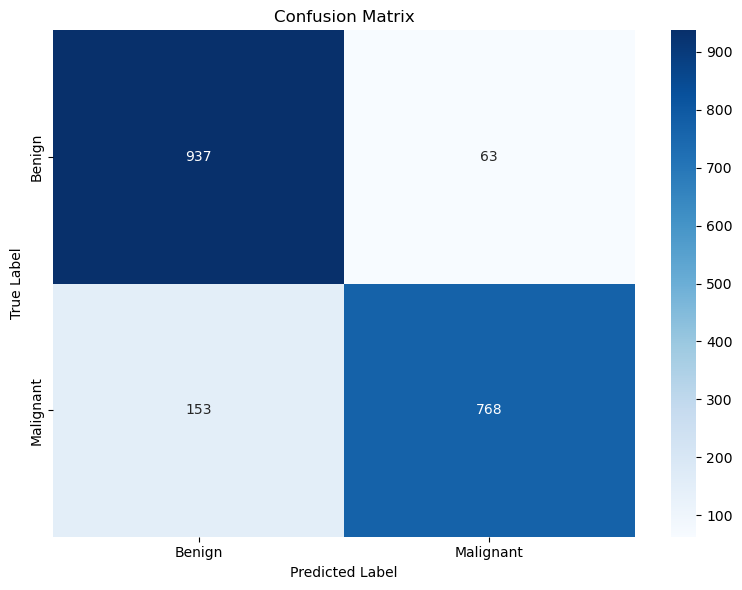

In [37]:
plot_confusion_matrix(test_labels,prediction)

### 32 batch - learning rate 0.02

In [67]:
cnn1 = CustomCNN((124,124,3),activation_function='relu', batch_size=32)
cnn1.compile(learning_rate = 0.02)
cnn1.train(train_data,train_labels,validation_data,5)

Epoch 1/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 49s 252ms/step - accuracy: 0.6144 - loss: 4.3215 - val_accuracy: 0.7144 - val_loss: 0.5825
Epoch 2/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 47s 243ms/step - accuracy: 0.6960 - loss: 0.5645 - val_accuracy: 0.7144 - val_loss: 0.7984
Epoch 3/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 47s 243ms/step - accuracy: 0.6828 - loss: 0.5725 - val_accuracy: 0.7144 - val_loss: 0.5867
Epoch 4/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 47s 244ms/step - accuracy: 0.6965 - loss: 0.5504 - val_accuracy: 0.6955 - val_loss: 0.5795
Epoch 5/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 47s 245ms/step - accuracy: 0.7031 - loss: 0.5542 - val_accuracy: 0.7267 - val_loss: 0.5759


In [69]:
prediction = cnn1.predict(test_images)

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step


In [71]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],  # Sınıf isimleri
)
print(report)

              precision    recall  f1-score   support

      benign       0.61      0.96      0.75      1000
   malignant       0.88      0.34      0.49       921

    accuracy                           0.66      1921
   macro avg       0.75      0.65      0.62      1921
weighted avg       0.74      0.66      0.62      1921



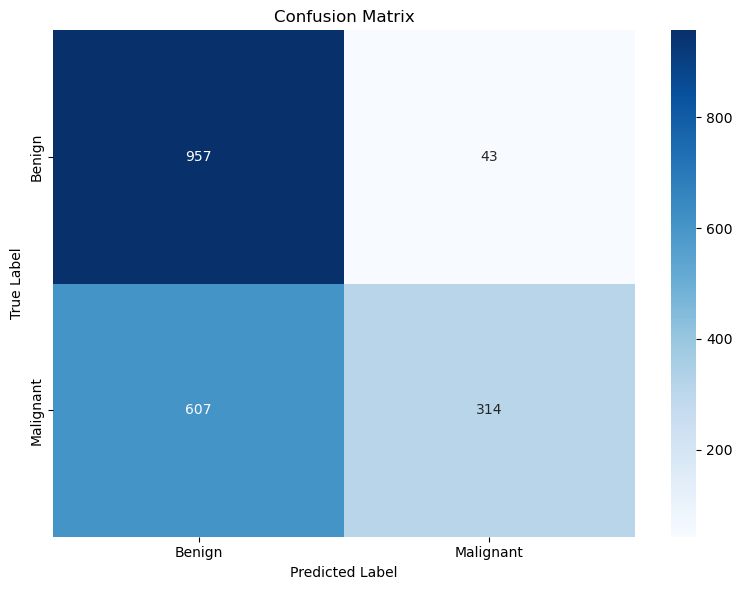

In [73]:
plot_confusion_matrix(test_labels,prediction)

### 16 batch - learning rate 0.005

In [49]:
cnn2 = CustomCNN((124,124,3),activation_function='relu', batch_size=16)

In [51]:
cnn2.compile(learning_rate = 0.005)
cnn2.train(train_data,train_labels,validatlion_data,5)

Epoch 1/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 57s 145ms/step - accuracy: 0.6694 - loss: 0.8397 - val_accuracy: 0.7560 - val_loss: 0.5302
Epoch 2/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 57s 147ms/step - accuracy: 0.7532 - loss: 0.4992 - val_accuracy: 0.8426 - val_loss: 0.4721
Epoch 3/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 52s 136ms/step - accuracy: 0.8299 - loss: 0.4330 - val_accuracy: 0.8595 - val_loss: 0.4459
Epoch 4/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 53s 137ms/step - accuracy: 0.8505 - loss: 0.3819 - val_accuracy: 0.8770 - val_loss: 0.3580
Epoch 5/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 52s 136ms/step - accuracy: 0.8756 - loss: 0.3156 - val_accuracy: 0.8881 - val_loss: 0.2932


In [53]:
prediction = cnn2.predict(test_images)

121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step


In [55]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],  # Sınıf isimleri
)
print(report)

              precision    recall  f1-score   support

      benign       0.84      0.91      0.87      1000
   malignant       0.90      0.81      0.85       921

    accuracy                           0.86      1921
   macro avg       0.87      0.86      0.86      1921
weighted avg       0.87      0.86      0.86      1921



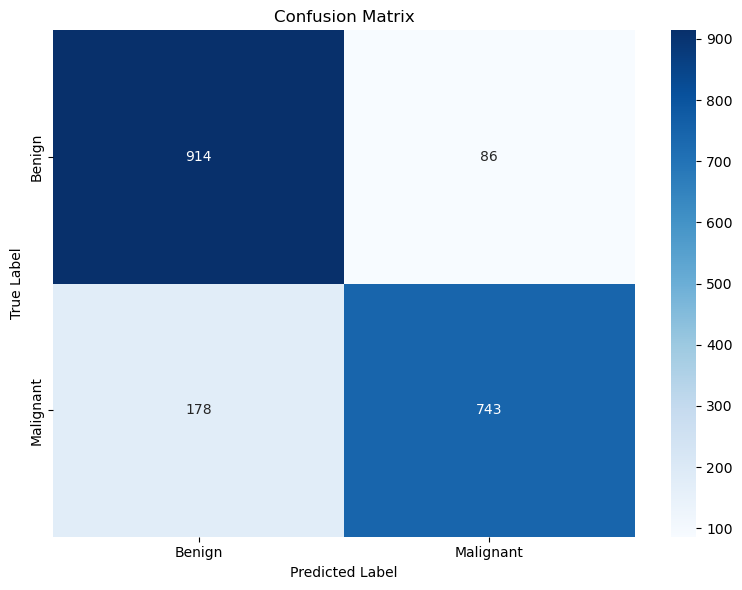

In [57]:
plot_confusion_matrix(test_labels,prediction)

### 16 batch - learning rate 0.02

In [85]:
cnn3 = CustomCNN((124,124,3),activation_function='relu', batch_size=16)
cnn3.compile(learning_rate = 0.02)
cnn3.train(train_data,train_labels,validation_data,5)

Epoch 1/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 58s 148ms/step - accuracy: 0.6580 - loss: 4.2923 - val_accuracy: 0.6831 - val_loss: 0.5904
Epoch 2/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 53s 137ms/step - accuracy: 0.6993 - loss: 0.5646 - val_accuracy: 0.7124 - val_loss: 0.5418
Epoch 3/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 53s 138ms/step - accuracy: 0.6969 - loss: 0.5523 - val_accuracy: 0.7222 - val_loss: 0.5281
Epoch 4/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 53s 139ms/step - accuracy: 0.6941 - loss: 0.5512 - val_accuracy: 0.7358 - val_loss: 0.5257
Epoch 5/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 54s 140ms/step - accuracy: 0.7030 - loss: 0.5526 - val_accuracy: 0.7222 - val_loss: 0.5363


In [87]:
prediction = cnn3.predict(test_images)

121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step


In [89]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],  # Sınıf isimleri
)
print(report)

              precision    recall  f1-score   support

      benign       0.61      0.97      0.75      1000
   malignant       0.91      0.32      0.47       921

    accuracy                           0.66      1921
   macro avg       0.76      0.65      0.61      1921
weighted avg       0.75      0.66      0.62      1921



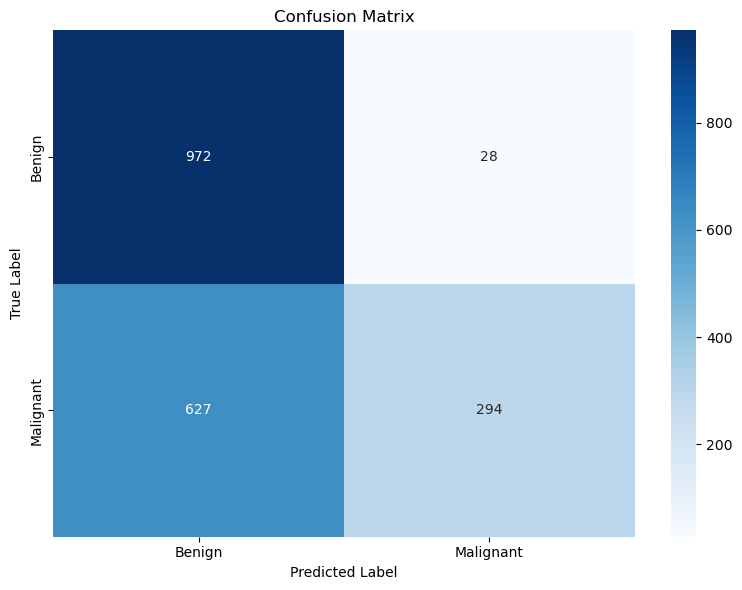

In [91]:
plot_confusion_matrix(test_labels,prediction)

## Sigmoid

### 32 batch - learning rate 0,005

In [106]:
cnn4 = CustomCNN((124,124,3),activation_function='sigmoid', batch_size=32)

In [108]:
cnn4.compile(learning_rate = 0.005)
cnn4.train(train_data,train_labels,validation_data,5)

Epoch 1/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 52s 265ms/step - accuracy: 0.4928 - loss: 1.3619 - val_accuracy: 0.4743 - val_loss: 0.6994
Epoch 2/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 49s 255ms/step - accuracy: 0.5030 - loss: 0.6997 - val_accuracy: 0.5257 - val_loss: 0.6919
Epoch 3/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 50s 258ms/step - accuracy: 0.5091 - loss: 0.6966 - val_accuracy: 0.4743 - val_loss: 0.6938
Epoch 4/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 50s 260ms/step - accuracy: 0.5110 - loss: 0.6974 - val_accuracy: 0.4743 - val_loss: 0.6997
Epoch 5/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 50s 259ms/step - accuracy: 0.5010 - loss: 0.6952 - val_accuracy: 0.5257 - val_loss: 0.6948


In [122]:
prediction = cnn4.predict(test_images)

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step


In [124]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],
    zero_division=0
)
print(report)

              precision    recall  f1-score   support

      benign       0.52      1.00      0.68      1000
   malignant       0.00      0.00      0.00       921

    accuracy                           0.52      1921
   macro avg       0.26      0.50      0.34      1921
weighted avg       0.27      0.52      0.36      1921



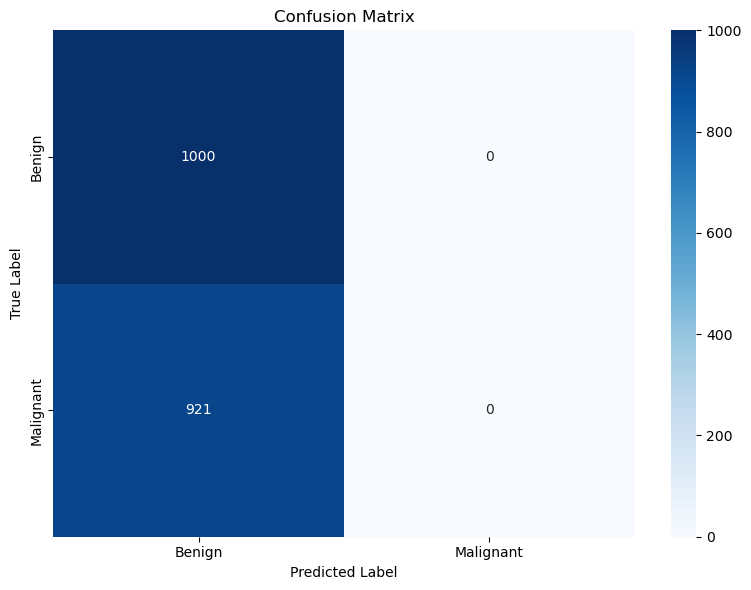

In [126]:
plot_confusion_matrix(test_labels,prediction)

### 32 batch - learning rate 0.02

In [128]:
cnn5 = CustomCNN((124,124,3),activation_function='sigmoid', batch_size=32)
cnn5.compile(learning_rate = 0.02)
cnn5.train(train_data,train_labels,validation_data,5)

Epoch 1/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 52s 266ms/step - accuracy: 0.5101 - loss: 1.0270 - val_accuracy: 0.5257 - val_loss: 0.7681
Epoch 2/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 49s 252ms/step - accuracy: 0.4894 - loss: 0.7265 - val_accuracy: 0.5257 - val_loss: 0.7005
Epoch 3/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 48s 250ms/step - accuracy: 0.5097 - loss: 0.7033 - val_accuracy: 0.5257 - val_loss: 0.7594
Epoch 4/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 48s 251ms/step - accuracy: 0.5024 - loss: 0.7289 - val_accuracy: 0.5257 - val_loss: 0.6920
Epoch 5/5
193/193 ━━━━━━━━━━━━━━━━━━━━ 48s 250ms/step - accuracy: 0.4822 - loss: 0.7075 - val_accuracy: 0.4743 - val_loss: 0.6942


In [130]:
prediction = cnn5.predict(test_images)

61/61 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step


In [132]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],
    zero_division=0
)
print(report)

              precision    recall  f1-score   support

      benign       0.00      0.00      0.00      1000
   malignant       0.48      1.00      0.65       921

    accuracy                           0.48      1921
   macro avg       0.24      0.50      0.32      1921
weighted avg       0.23      0.48      0.31      1921



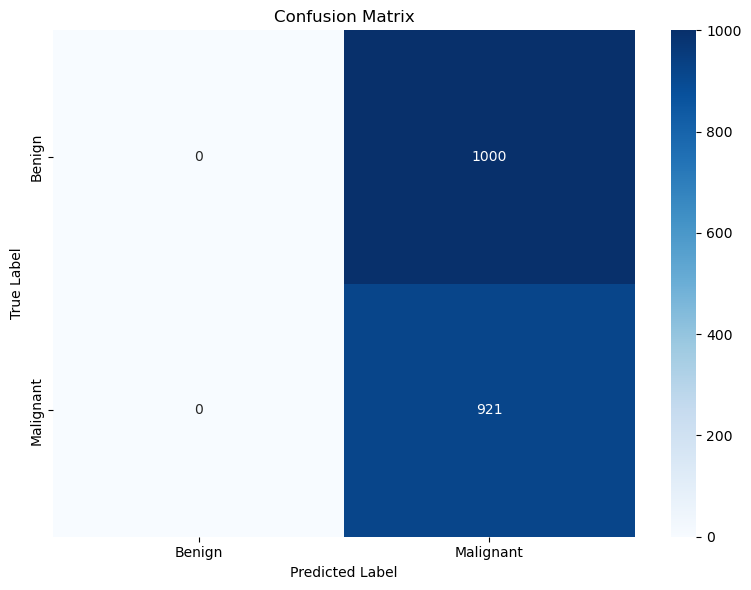

In [134]:
plot_confusion_matrix(test_labels,prediction)

### 16 batch - learning rate 0.005

In [136]:
cnn6 = CustomCNN((124,124,3),activation_function='sigmoid', batch_size=16)

In [138]:
cnn6.compile(learning_rate = 0.005)
cnn6.train(train_data,train_labels,validation_data,5)

Epoch 1/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 62s 159ms/step - accuracy: 0.5130 - loss: 1.0425 - val_accuracy: 0.4743 - val_loss: 0.7643
Epoch 2/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 55s 143ms/step - accuracy: 0.4866 - loss: 0.7008 - val_accuracy: 0.5257 - val_loss: 0.6920
Epoch 3/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 58s 150ms/step - accuracy: 0.5115 - loss: 0.7005 - val_accuracy: 0.5257 - val_loss: 0.7054
Epoch 4/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 57s 149ms/step - accuracy: 0.5096 - loss: 0.7035 - val_accuracy: 0.5257 - val_loss: 0.6939
Epoch 5/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 56s 145ms/step - accuracy: 0.5004 - loss: 0.7031 - val_accuracy: 0.4743 - val_loss: 0.6954


In [140]:
prediction = cnn6.predict(test_images)

121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step


In [142]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],
    zero_division=0
)
print(report)

              precision    recall  f1-score   support

      benign       0.00      0.00      0.00      1000
   malignant       0.48      1.00      0.65       921

    accuracy                           0.48      1921
   macro avg       0.24      0.50      0.32      1921
weighted avg       0.23      0.48      0.31      1921



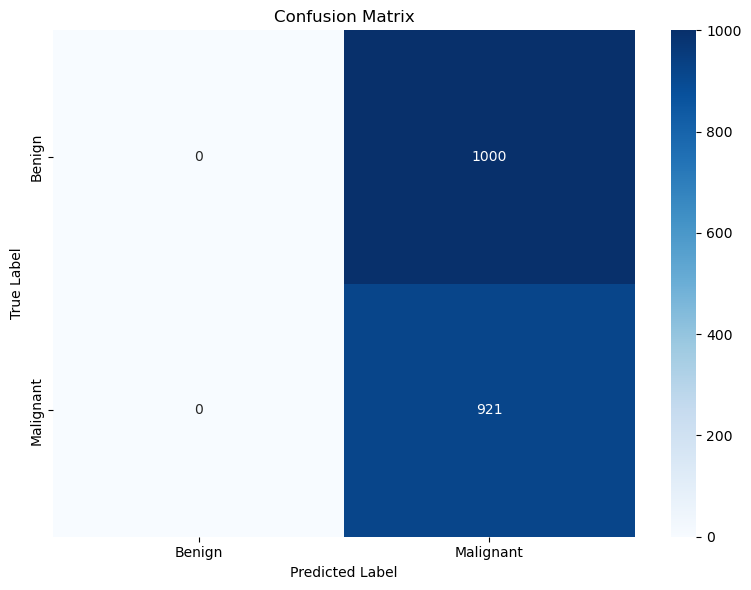

In [144]:
plot_confusion_matrix(test_labels,prediction)

### 16 batch - learning rate 0.02

In [146]:
cnn7 = CustomCNN((124,124,3),activation_function='sigmoid', batch_size=16)

In [148]:
cnn7.compile(learning_rate = 0.02)
cnn7.train(train_data,train_labels,validation_data,5)

Epoch 1/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 58s 148ms/step - accuracy: 0.4936 - loss: 0.8687 - val_accuracy: 0.5257 - val_loss: 0.8460
Epoch 2/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 55s 141ms/step - accuracy: 0.5192 - loss: 0.7422 - val_accuracy: 0.4743 - val_loss: 0.6939
Epoch 3/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 55s 142ms/step - accuracy: 0.4975 - loss: 0.7178 - val_accuracy: 0.5257 - val_loss: 0.6969
Epoch 4/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 55s 142ms/step - accuracy: 0.5150 - loss: 0.7156 - val_accuracy: 0.5257 - val_loss: 0.7067
Epoch 5/5
385/385 ━━━━━━━━━━━━━━━━━━━━ 54s 141ms/step - accuracy: 0.5043 - loss: 0.7280 - val_accuracy: 0.5257 - val_loss: 0.6919


In [150]:
prediction = cnn7.predict(test_images)

121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step


In [152]:
report = classification_report(
    test_labels,
    prediction,
    target_names=['benign', 'malignant'],
    zero_division=0
)
print(report)

              precision    recall  f1-score   support

      benign       0.52      1.00      0.68      1000
   malignant       0.00      0.00      0.00       921

    accuracy                           0.52      1921
   macro avg       0.26      0.50      0.34      1921
weighted avg       0.27      0.52      0.36      1921



# Experiments for CNN

| Experiment | Model |  Input Size  | Batch Size | Activation Func  | Learning Rate | Accuracy |
|------------|-------|--------------|------------|------------------|---------------|----------|
| 1          | CNN   |  124x124x3   | 32         | ReLu             | 0.005         | 0.89     |
| 2          | CNN   |  124x124x3   | 32         | ReLu             | 0.02          | 0.66     |
| 3          | CNN   |  124x124x3   | 16         | ReLu             | 0.005         | 0.86     |
| 4          | CNN   |  124x124x3   | 16         | ReLu             | 0.02          | 0.66     |
| 5          | CNN   |  124x124x3   | 32         | Sigmoid          | 0.005         | 0.52     |
| 6          | CNN   |  124x124x3   | 32         | Sigmoid          | 0.02          | 0.48     |
| 7          | CNN   |  124x124x3   | 16         | Sigmoid          | 0.005         | 0.48     |
| 8          | CNN   |  124x124x3   | 16         | Sigmoid          | 0.02          | 0.48     |


Sigmoid vs ReLu

After experimenting with different hyperparameters, I observed a significant difference between the ReLU and Sigmoid activation functions. This occurs because, when Sigmoid is used in hidden layers, the vanishing gradient problem arises. Sigmoid maps all weights to a range between 0 and 1, causing gradients to become very small and the weights to lose their significance. This is the vanishing gradient issue. In contrast, ReLU prevents this problem by allowing gradients to propagate effectively, maintaining meaningful weight updates.

Learning Rate

When examining the impact of the learning rate in experiments using ReLU activation, it is evident that the learning rate significantly affects the model’s performance. Based on precision, recall, and F1-score analysis, experiments 2 and 4 appear to be stuck in a local minimum, predominantly classifying most images as benign. However, when these models classify an image as malignant, the predictions are highly accurate. This indicates that these two models are biased towards benign classifications but are very reliable when predicting malignancy. In contrast, experiments 1 and 3 demonstrate a much better balance in classification and regularization, achieving more consistent performance across both classes.

Batch Size

When examining the impact of batch size on the models, there is no significant difference observed in performance. This suggests that batch size does not have a notable effect on the outcomes in these experiments.

# Multi Layer Neural Network

### create 50x50 input for experiment 

In [154]:
train_resized_images = [cv2.resize(img, (50, 50), interpolation=cv2.INTER_AREA) for img in train_images]
train_resized_images = np.array(train_resized_images)

test_resized_images = [cv2.resize(img, (50, 50), interpolation=cv2.INTER_AREA) for img in test_images]
test_resized_images = np.array(test_resized_images)

In [156]:
print(train_resized_images.shape)
print(test_resized_images.shape)

(7684, 50, 50, 3)
(1921, 50, 50, 3)


### flatten the inputs for putting in the neural network

In [158]:
flattened_images5050 = train_resized_images.reshape(train_resized_images.shape[0], -1)
flattened_images124124 = train_images.reshape(train_images.shape[0],-1)

In [160]:
testFlatten5050 = test_resized_images.reshape(test_resized_images.shape[0],-1)
testFlatten124124 = test_images.reshape(test_images.shape[0],-1)

In [162]:
print(flattened_images5050.shape)
print(flattened_images124124.shape)
print(testFlatten5050.shape)
print(testFlatten124124.shape)

(7684, 7500)
(7684, 46128)
(1921, 7500)
(1921, 46128)


In [164]:
input124 = flattened_images124124
input124 = np.array(input124)
test124 = testFlatten124124
test124 = np.array(test124)

In [166]:
input50 = flattened_images5050
test50 = testFlatten5050

# createMultiLayerNeuralNetwork:
function builds, compiles, trains, and evaluates a simple feedforward neural network for binary classification tasks. The model consists of three dense layers, including an output layer with a sigmoid activation function to predict probabilities. It uses the SGD optimizer with a configurable learning rate and trains on the provided training data with a specified batch size and activation function. After training, the function predicts the classes for the test data, generates a classification report with metrics like precision, recall, and F1-score, and visualizes the results using a confusion matrix plot.

In [168]:
def createMultiLayerNeuralNetwork(X_train,y_train,X_test,y_test ,activation_func= 'relu',learningRate= 0.005, batch = 16):
    model = Sequential([
    Dense(128, activation=activation_func, input_shape=(X_train.shape[1],)),  
    Dense(64, activation=activation_func),  
    Dense(1, activation='sigmoid')
    ])
    
    model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=learningRate),
    loss='binary_crossentropy',
    metrics=['accuracy']
    )
    
    model.fit(X_train, y_train, epochs=10, batch_size=batch) 

    predictions = model.predict(X_test)

    predicted_classes = (predictions > 0.5).astype(int)
    report = classification_report(
        y_test,
        predicted_classes,
        target_names=['benign', 'malignant'],
        zero_division=0
    )
    print(report)
    plot_confusion_matrix(y_test,predicted_classes)

# ReLu - 124 - 0.005 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6678 - loss: 0.6418
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8046 - loss: 0.4066
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8365 - loss: 0.3601
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8401 - loss: 0.3398
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8498 - loss: 0.3389
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8559 - loss: 0.3293
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8517 - loss: 0.3201
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8559 - loss: 0.3147
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8655 - loss: 0.3063
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8642 - loss: 0.2981
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

      benign       0.83      0.94      0.88 

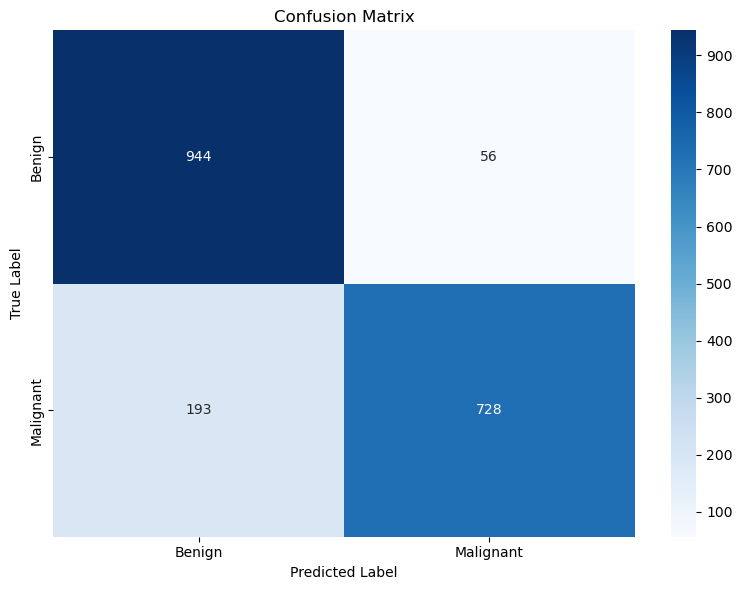

In [178]:
createMultiLayerNeuralNetwork(input124,train_labelsFirst,test124,test_labels)

# ReLu- 50 - 0.005 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7050 - loss: 0.5611
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8035 - loss: 0.4138
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8293 - loss: 0.3580
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8389 - loss: 0.3493
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8444 - loss: 0.3345
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8526 - loss: 0.3298
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8581 - loss: 0.3097
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8696 - loss: 0.3042
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8699 - loss: 0.2980
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8774 - loss: 0.2838
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

      benign       0.87      0.90      0.88

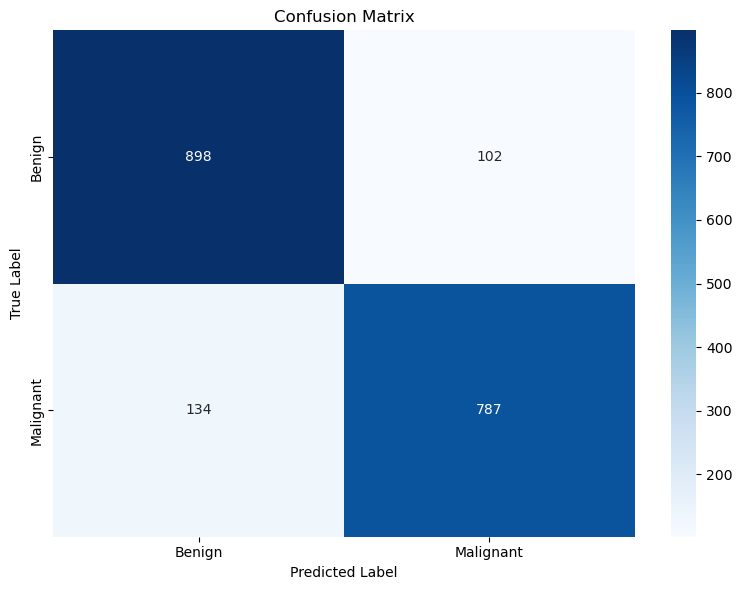

In [180]:
createMultiLayerNeuralNetwork(input50,train_labelsFirst,test50,test_labels)

# ReLu- 124 - 0.02 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.6189 - loss: 1.0681
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7554 - loss: 0.4917
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7984 - loss: 0.4337
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8202 - loss: 0.3870
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8319 - loss: 0.3844
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8312 - loss: 0.3723
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8436 - loss: 0.3444
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8394 - loss: 0.3423
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8478 - loss: 0.3513
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8468 - loss: 0.3362
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

      benign       0.86      0.89      0.87  

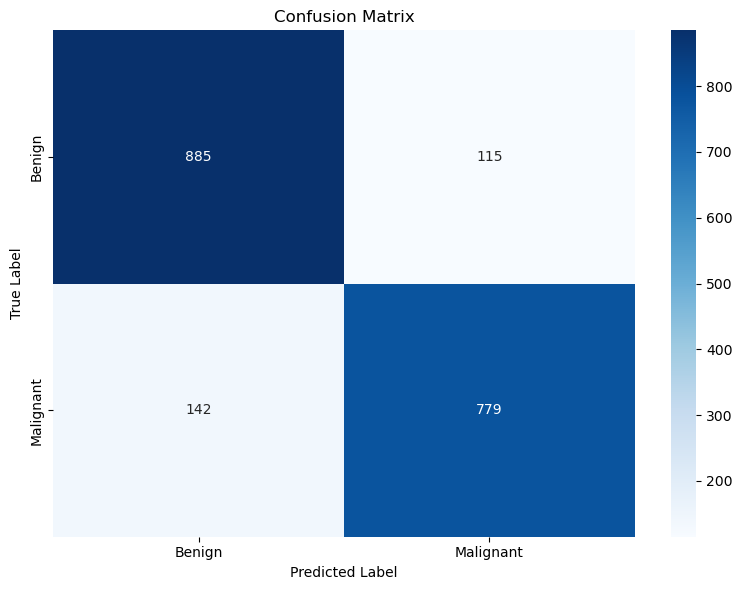

In [185]:
createMultiLayerNeuralNetwork(input124,train_labelsFirst,test124,test_labels,learningRate = 0.02)

# ReLu - 50 - 0.02 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6738 - loss: 0.6001
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7935 - loss: 0.4250
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8238 - loss: 0.3765
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8287 - loss: 0.3613
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8434 - loss: 0.3458
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8649 - loss: 0.3212
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8596 - loss: 0.3206
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8626 - loss: 0.3093
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8650 - loss: 0.3065
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8717 - loss: 0.2932
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

      benign       0.90      0.81      0.85

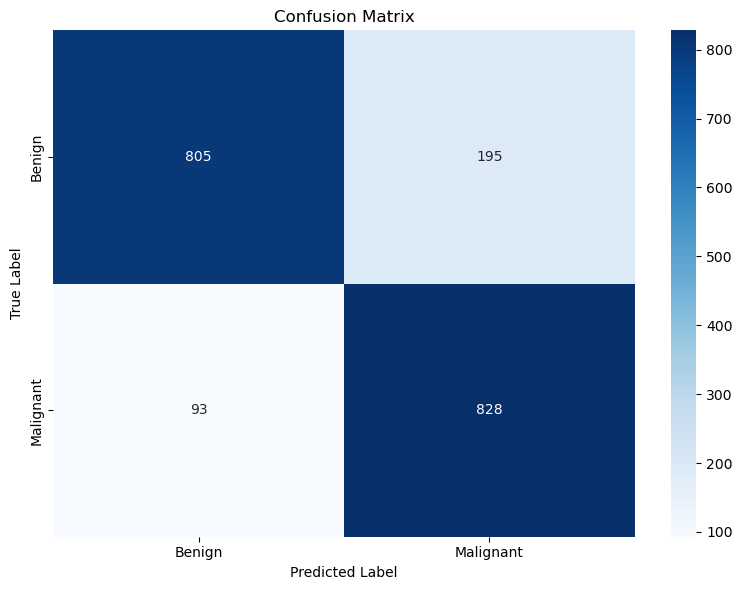

In [187]:
createMultiLayerNeuralNetwork(input50,train_labelsFirst,test50,test_labels,learningRate=0.02)

# Sigmoid - 124 - 0.005

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.6239 - loss: 0.6605
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7350 - loss: 0.6068
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7943 - loss: 0.5494
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8224 - loss: 0.4889
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8247 - loss: 0.4420
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8220 - loss: 0.4134
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8285 - loss: 0.3893
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8368 - loss: 0.3709
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8423 - loss: 0.3537
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8461 - loss: 0.3504
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

      benign       0.78      0.94      0.85  

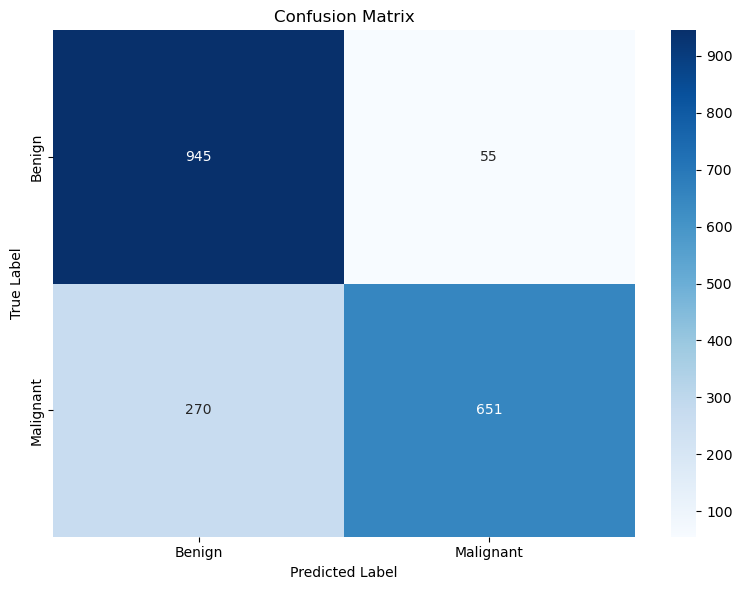

In [189]:
createMultiLayerNeuralNetwork(input124,train_labelsFirst,test124,test_labels,activation_func='sigmoid')

# Sigmoid - 50 - 0.005 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5453 - loss: 0.6885
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6768 - loss: 0.6512
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6878 - loss: 0.6337
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7238 - loss: 0.6094
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7491 - loss: 0.5872
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7868 - loss: 0.5513
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8109 - loss: 0.5179
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8164 - loss: 0.4789
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8273 - loss: 0.4488
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8205 - loss: 0.4254
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

      benign       0.82      0.92      0.87

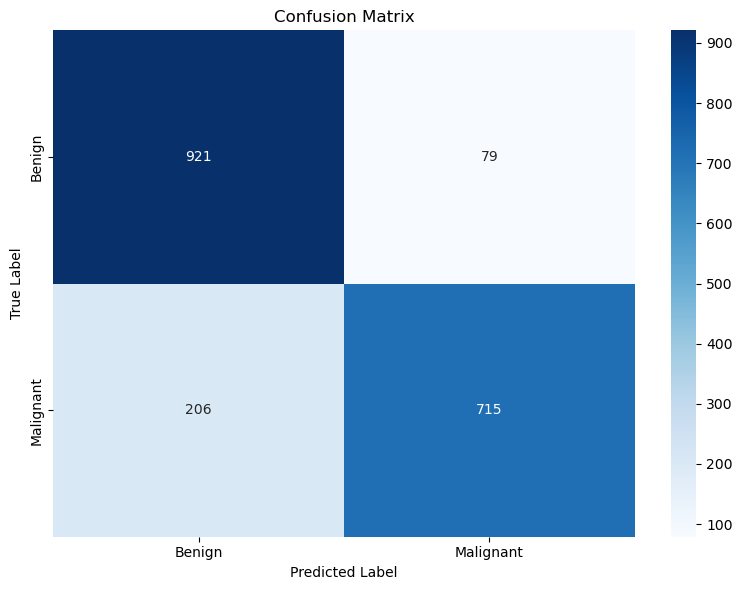

In [191]:
createMultiLayerNeuralNetwork(input50,train_labelsFirst,test50,test_labels,activation_func='sigmoid')

# Sigmoid - 124 - 0.02 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6654 - loss: 0.6278
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8049 - loss: 0.4521
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8292 - loss: 0.3880
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8377 - loss: 0.3650
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8364 - loss: 0.3625
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8437 - loss: 0.3448
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8482 - loss: 0.3414
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8547 - loss: 0.3298
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8633 - loss: 0.3112
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8568 - loss: 0.3247
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

      benign       0.85      0.91      0.88 

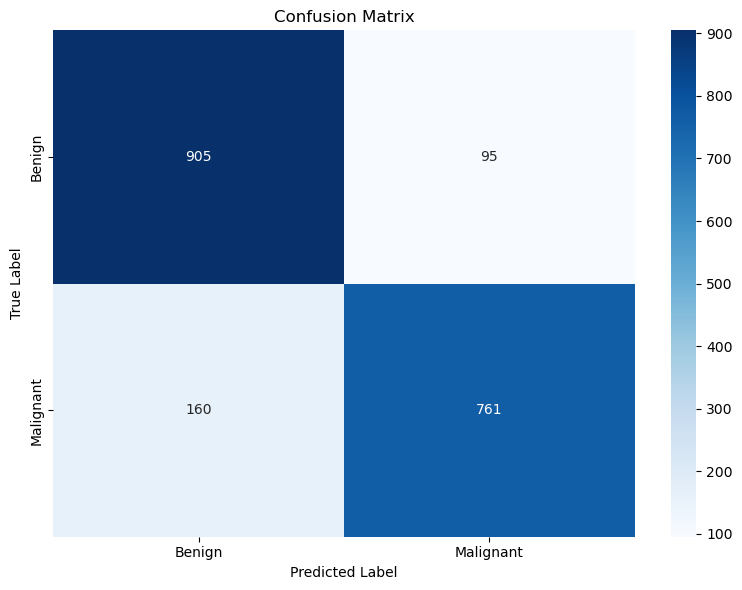

In [197]:
createMultiLayerNeuralNetwork(input124,train_labelsFirst,test124,test_labels,activation_func='sigmoid',learningRate=0.02)

# Sigmoid - 50 - 0.02 LR

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6101 - loss: 0.6642
Epoch 2/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7509 - loss: 0.5755
Epoch 3/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8150 - loss: 0.4476
Epoch 4/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8246 - loss: 0.3842
Epoch 5/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8401 - loss: 0.3588
Epoch 6/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8354 - loss: 0.3567
Epoch 7/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8408 - loss: 0.3413
Epoch 8/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8387 - loss: 0.3533
Epoch 9/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8355 - loss: 0.3499
Epoch 10/10
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8518 - loss: 0.3270
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

      benign       0.86      0.88      0.87

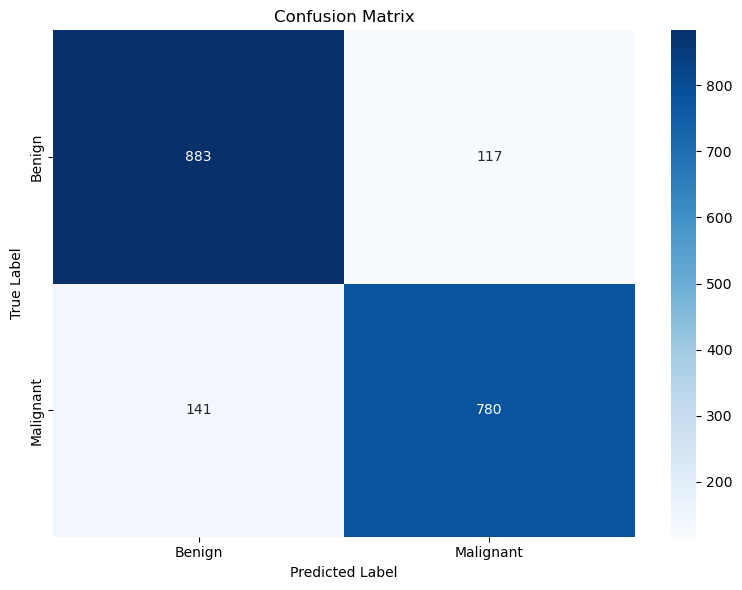

In [205]:
createMultiLayerNeuralNetwork(input50,train_labelsFirst,test50,test_labels,activation_func='sigmoid',learningRate = 0.02)

| Experiment | Model | Input Size  | Batch Size | Activation Func  | Learning Rate | Accuracy |
|------------|-------|-------------|------------|------------------|---------------|----------|
| 1          | MLNN  | 124x124x3   | 16         | ReLu             | 0.005         | 0.87     |
| 2          | MLNN  | 50x50x3     | 16         | ReLu             | 0.005         | 0.88     |
| 3          | MLNN  | 124x124x3   | 16         | ReLu             | 0.02          | 0.87     |
| 4          | MLNN  | 50x50x3     | 16         | ReLu             | 0.02          | 0.85     |
| 5          | MLNN  | 124x124x3   | 16         | Sigmoid          | 0.005         | 0.83     |
| 6          | MLNN  | 50x50x3     | 16         | Sigmoid          | 0.005         | 0.85     |
| 7          | MLNN  | 124x124x3   | 16         | Sigmoid          | 0.02          | 0.87     |
| 8          | MLNN  | 50x50x3     | 16         | Sigmoid          | 0.02          | 0.87     |

Input Size 

When comparing input sizes of 124x124x3 and 50x50x3, there is no significant difference between experiments. In some experiments smaller input size give better performance in some experiments bigger size give better performance so that I couldn't say anything with looking these experiments but if we would used bigger input than 124x124 like 300x300 our input size will be so much much bigger and it will take so much time to train the model after this time cost would it give so much better performance than this inputs I don't think like that.

Activation Function

Comparing the two activation functions, ReLU consistently outperforms Sigmoid in terms of accuracy. For ReLU (Experiments 1-4), accuracy ranges from 85% to 88%, whereas Sigmoid (Experiments 5-8) achieves slightly lower accuracy, ranging from 83% to 87%. ReLU is known to avoid the vanishing gradient problem, allowing deeper layers to learn effectively, which explains its superior performance. On the other hand, Sigmoid tends to struggle in deeper networks due to its tendency to squash values between 0 and 1, leading to diminished gradients and slower learning but when because of we are not using so much deep model there is no significant performance difference between relu and sigmoid in this experiments.

Learning Rate

The learning rate seems to have minimal impact on ReLU’s performance. For both 0.005 and 0.02 learning rates, the accuracy remains consistent (85%-88%, Experiments 1-4). However, for Sigmoid, the learning rate makes a noticeable difference. At a lower learning rate of 0.005, accuracy is slightly lower (83%-85%, Experiments 5, 6), whereas at 0.02, accuracy improves to 87% (Experiments 7, 8). This indicates that Sigmoid may benefit from higher learning rates to compensate for its slower gradient flow but I want to say again there is no big difference between performances.

| Experiment | Model |  Input Size  | Batch Size | Activation Func  | Learning Rate | Accuracy |
|------------|-------|--------------|------------|------------------|---------------|----------|
| 1          | CNN   |  124x124x3   | 32         | ReLu             | 0.005         | 0.89     |
| 2          | CNN   |  124x124x3   | 32         | ReLu             | 0.02          | 0.66     |
| 3          | CNN   |  124x124x3   | 16         | ReLu             | 0.005         | 0.86     |
| 4          | CNN   |  124x124x3   | 16         | ReLu             | 0.02          | 0.66     |
| 5          | CNN   |  124x124x3   | 32         | Sigmoid          | 0.005         | 0.52     |
| 6          | CNN   |  124x124x3   | 32         | Sigmoid          | 0.02          | 0.48     |
| 7          | CNN   |  124x124x3   | 16         | Sigmoid          | 0.005         | 0.48     |
| 8          | CNN   |  124x124x3   | 16         | Sigmoid          | 0.02          | 0.48     |
| 1          | MLNN  | 124x124x3    | 16         | ReLu             | 0.005         | 0.87     |
| 2          | MLNN  | 50x50x3      | 16         | ReLu             | 0.005         | 0.88     |
| 3          | MLNN  | 124x124x3    | 16         | ReLu             | 0.02          | 0.87     |
| 4          | MLNN  | 50x50x3      | 16         | ReLu             | 0.02          | 0.85     |
| 5          | MLNN  | 124x124x3    | 16         | Sigmoid          | 0.005         | 0.83     |
| 6          | MLNN  | 50x50x3      | 16         | Sigmoid          | 0.005         | 0.85     |
| 7          | MLNN  | 124x124x3    | 16         | Sigmoid          | 0.02          | 0.87     |
| 8          | MLNN  | 50x50x3      | 16         | Sigmoid          | 0.02          | 0.87     |

# Conclusion

When working on image classification tasks, the first decision to make is whether to use a Convolutional Neural Network (CNN) or a Multi-Layer Neural Network (MLNN). Based on research, CNNs are generally more effective for large datasets, as they are designed to capture spatial features in images efficiently. However, in our experiments, the dataset is relatively small, with 7,684 training examples and 1,921 test examples. Due to the limited size of our dataset, both MLNN and CNN models achieve similar performances at their best. This suggests that the advantages of CNNs, such as their ability to learn hierarchical spatial features, may not fully manifest when the dataset is small, allowing simpler MLNN models to perform competitively. 

When examining the CNN model, the learning rate and activation function significantly impact its performance. Using a learning rate of 0.02 with ReLU often causes the model to get stuck in a local minimum or exhibit oscillating behavior. Additionally, with this learning rate, the model tends to classify most examples as benign. This suggests that a learning rate of 0.02 results in slight underfitting, as it does not perform well on the training data either. In contrast, using a learning rate of 0.005 with ReLU achieves the best performance for the CNN. This is because ReLU is an effective activation function for hidden layers, and 0.005 is an optimal learning rate—neither too small nor too large. A learning rate of 0.02, by comparison, is relatively high. When examining batch sizes, there seems to be no noticeable effect on performance within the tested range. However, using much larger batch sizes could slow down the learning process, which would be worth investigating further.

When examining the MLNN models,there is no big difference between all of the experiments sigmoid is not effect the model performance as CNN and give close performance to ReLu. 0.005 learning rate is better with ReLu but 0.02 is better with sigmoid but I think this results doesn't mean so much thing because there is no big difference between results.  

